In [2]:
import xml.etree.ElementTree as ET
from pathlib import Path
import pandas as pd

root_dir = Path(r"D:\DATA\idd_raw\IDD_Detection")
ann_dir = root_dir / "Annotations"

rows = []
for xml_path in ann_dir.rglob("*.xml"):
    rel = xml_path.relative_to(ann_dir).with_suffix("")   # camera/sequence/frame
    root = ET.parse(xml_path).getroot()
    w = int(root.find("size/width").text)
    h = int(root.find("size/height").text)
    for obj in root.findall("object"):
        b = obj.find("bndbox")
        rows.append({
            "id": rel.as_posix(), "camera": rel.parts[0], "sequence": rel.parts[1],
            "w": w, "h": h, "cls": obj.find("name").text,
            "xmin": int(float(b.find("xmin").text)),
            "ymin": int(float(b.find("ymin").text)),
            "xmax": int(float(b.find("xmax").text)),
            "ymax": int(float(b.find("ymax").text)),
        })
df = pd.DataFrame(rows)
df["area"] = (df.xmax - df.xmin) * (df.ymax - df.ymin)
df["rel_area"] = df["area"] / (df.w * df.h)
from pathlib import Path
out = Path("..") / "data" / "annotations.parquet"
out.parent.mkdir(exist_ok=True)
df.to_parquet(out)

print(df.shape, df.id.nunique(), "images,", df.sequence.nunique(), "sequences")
print(df.groupby("camera").id.nunique())
print(df.cls.value_counts())

(507576, 12) 41794 images, 557 sequences
camera
frontFar            4496
frontNear           5052
highquality_16k    14722
rearNear            2130
sideLeft            7549
sideRight           7845
Name: id, dtype: int64
cls
motorcycle          103608
rider                97626
car                  90520
person               88397
autorickshaw         32280
truck                27837
vehicle fallback     21081
bus                  18745
traffic sign         14203
animal                6224
traffic light         3699
bicycle               3142
caravan                136
train                   60
trailer                 18
Name: count, dtype: int64


In [3]:
from pathlib import Path
out = Path("..") / "data" / "annotations.parquet"
out.parent.mkdir(exist_ok=True)
df.to_parquet(out)
print(df.shape, df.id.nunique(), "images,", df.sequence.nunique(), "sequences")
print(df.groupby("camera").id.nunique())
print(df.cls.value_counts())

(507576, 12) 41794 images, 557 sequences
camera
frontFar            4496
frontNear           5052
highquality_16k    14722
rearNear            2130
sideLeft            7549
sideRight           7845
Name: id, dtype: int64
cls
motorcycle          103608
rider                97626
car                  90520
person               88397
autorickshaw         32280
truck                27837
vehicle fallback     21081
bus                  18745
traffic sign         14203
animal                6224
traffic light         3699
bicycle               3142
caravan                136
train                   60
trailer                 18
Name: count, dtype: int64


In [ ]:
print(df.groupby("camera")[["w", "h"]].agg(["min", "max"]))

                    w           h      
                  min   max   min   max
camera                                 
frontFar         1280  1280   964   964
frontNear        1920  1920  1080  1080
highquality_16k  1280  1921   720  1080
rearNear         1920  1920  1080  1080
sideLeft         1920  1920  1080  1080
sideRight        1920  1920  1080  1080


In [ ]:
pd.crosstab(df.cls, df.camera)

camera,frontFar,frontNear,highquality_16k,rearNear,sideLeft,sideRight
cls,,,,,,
animal,877,817,1941,150,1500,939
autorickshaw,859,987,25920,1064,1703,1747
bicycle,215,301,1476,132,515,503
bus,336,1727,12073,965,1391,2253
car,2401,5288,63560,4447,5850,8974
caravan,2,8,26,1,91,8
motorcycle,4075,5416,75307,3300,7742,7768
person,3062,4736,63532,1628,8289,7150
rider,4494,5316,72893,3286,5371,6266


In [ ]:
df.groupby("cls").rel_area.median().sort_values()

cls
animal              0.000428
vehicle fallback    0.000492
traffic light       0.000500
traffic sign        0.000523
person              0.001008
rider               0.001155
motorcycle          0.001914
car                 0.002684
autorickshaw        0.003051
bicycle             0.003079
train               0.004197
truck               0.005762
bus                 0.009578
trailer             0.011491
caravan             0.063346
Name: rel_area, dtype: float64

In [7]:
import pandas as pd, numpy as np, cv2, matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_parquet("../data/annotations.parquet")
root_dir = Path(r"D:\DATA\idd_raw\IDD_Detection")

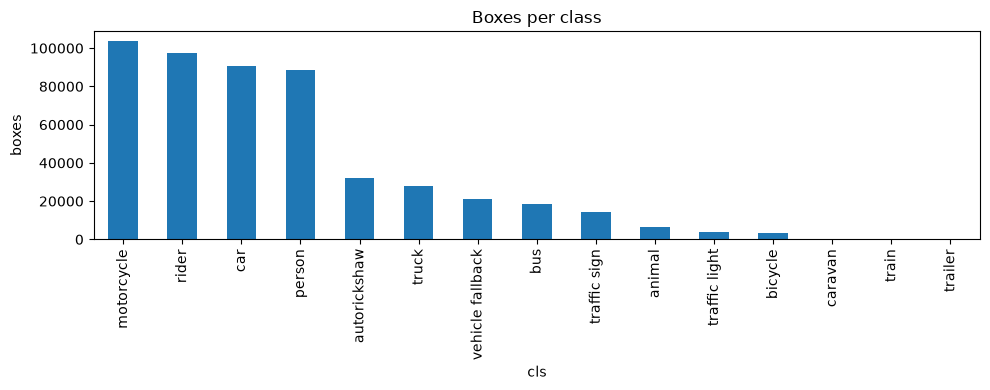

In [ ]:
#boxes per class
df.cls.value_counts().plot.bar(figsize=(10, 4), title="Boxes per class")
plt.ylabel("boxes"); plt.tight_layout(); plt.show()

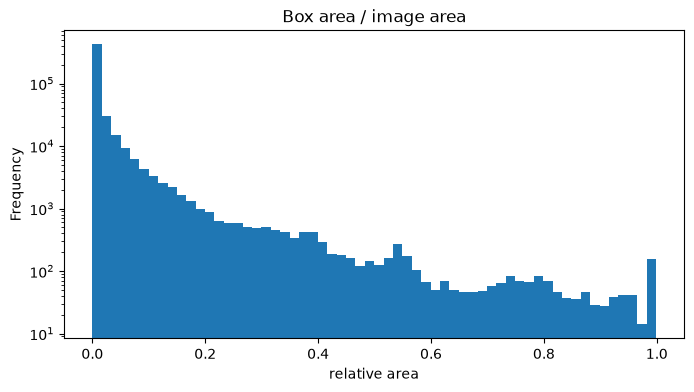

0.4109433858180844 of boxes cover under 0.1% of the image


In [ ]:
#box size (fraction of image area), log scale
df.rel_area.plot.hist(bins=60, logy=True, figsize=(8, 4), title="Box area / image area")
plt.xlabel("relative area"); plt.show()
print((df.rel_area < 0.001).mean(), "of boxes cover under 0.1% of the image")

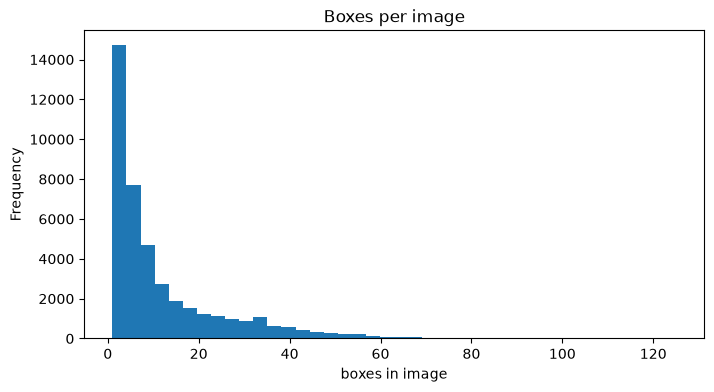

count    41794.000000
mean        12.144710
std         13.534508
min          1.000000
25%          3.000000
50%          7.000000
75%         16.000000
max        125.000000
dtype: float64


In [ ]:
#boxes per image
bpi = df.groupby("id").size()
bpi.plot.hist(bins=40, figsize=(8, 4), title="Boxes per image")
plt.xlabel("boxes in image"); plt.show()
print(bpi.describe())

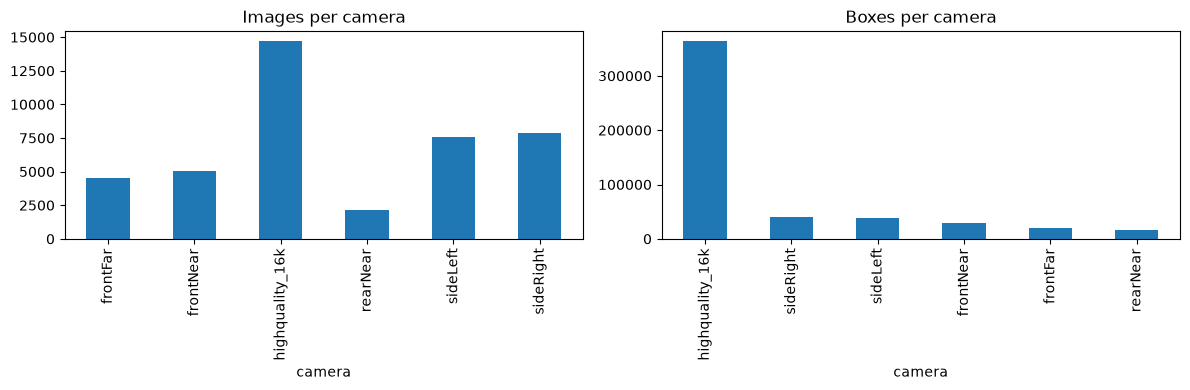

In [11]:
#images and boxes per camera
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("camera").id.nunique().plot.bar(ax=ax[0], title="Images per camera")
df.camera.value_counts().plot.bar(ax=ax[1], title="Boxes per camera")
plt.tight_layout(); plt.show()

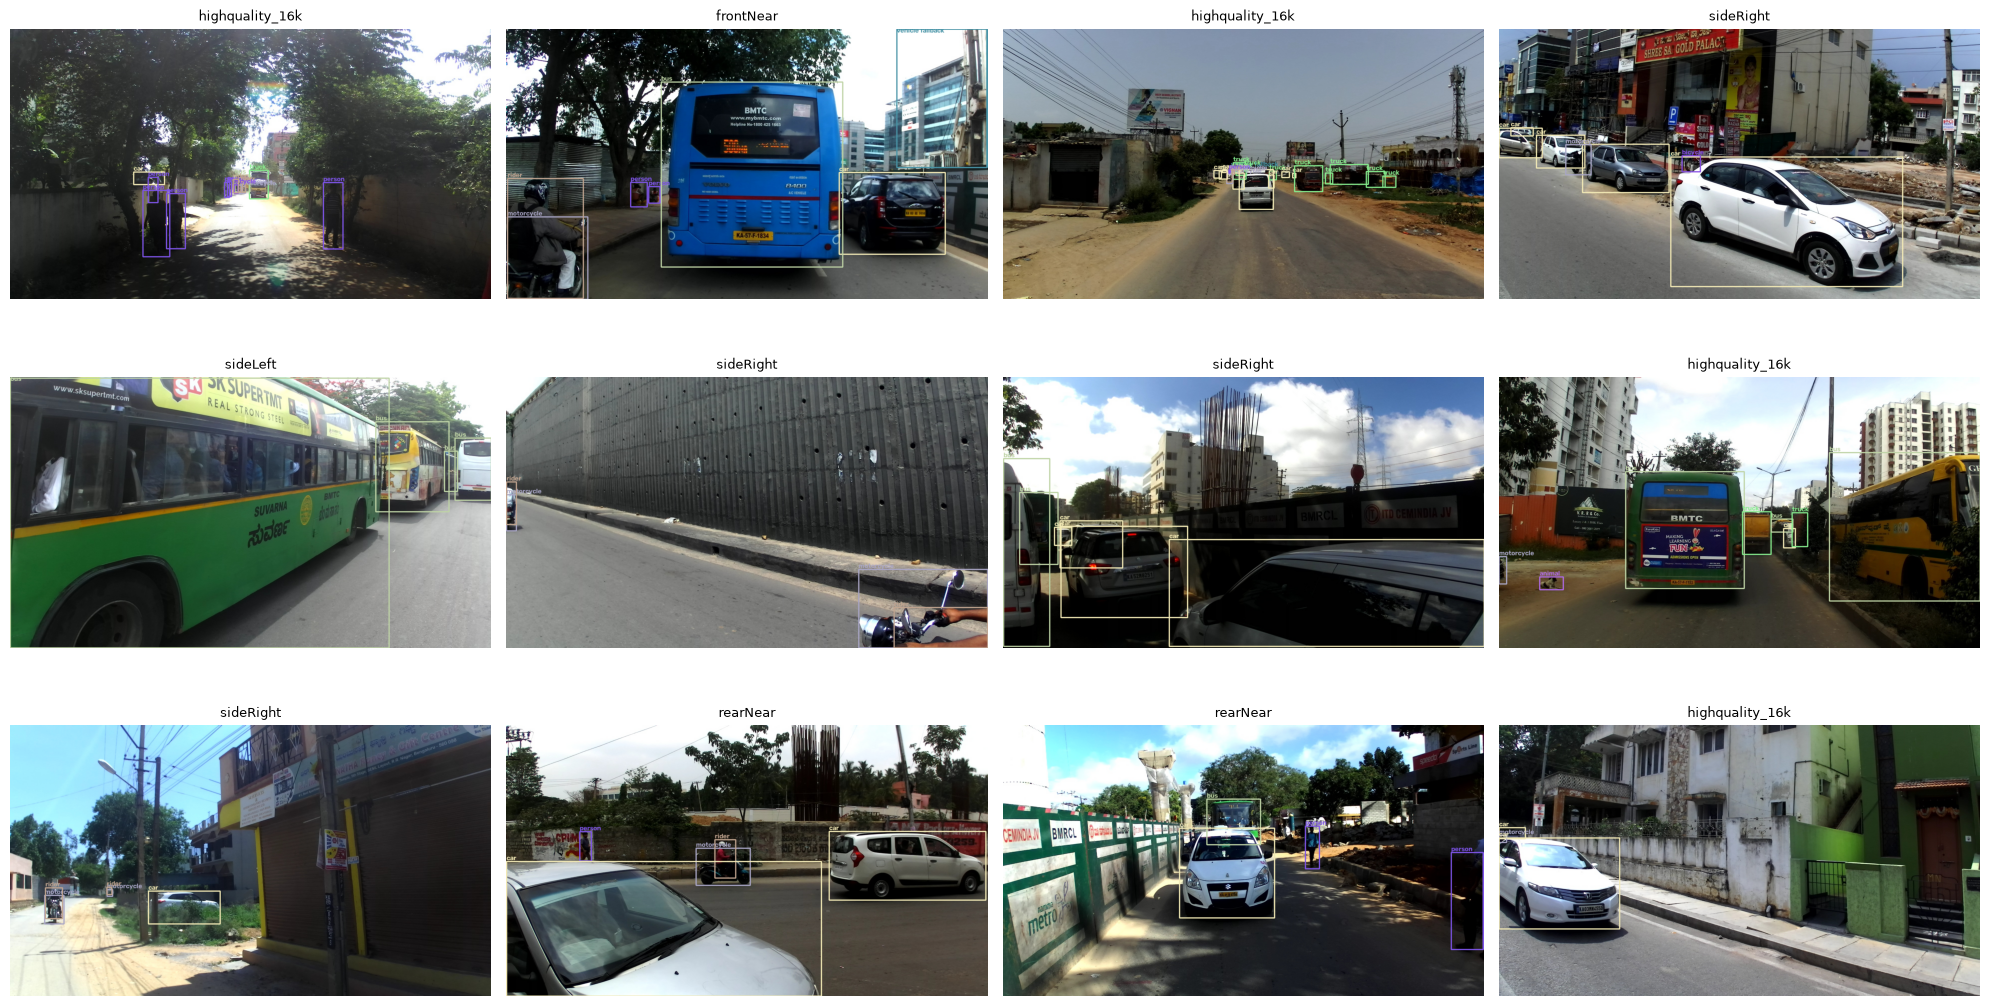

In [17]:
#random image with boxes
colors = {c: tuple(int(x) for x in np.random.RandomState(i).randint(60, 255, 3))
          for i, c in enumerate(sorted(df.cls.unique()))}

ids = np.random.choice(df.id.unique(), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, img_id in zip(axes.ravel(), ids):
    img = cv2.imread(str(root_dir / "JPEGImages" / (img_id + ".jpg")))
    if img is None:
        ax.set_title("image not found"); ax.axis("off"); continue
    for r in df[df.id == img_id].itertuples():
        cv2.rectangle(img, (r.xmin, r.ymin), (r.xmax, r.ymax), colors[r.cls], 3)
        cv2.putText(img, r.cls, (r.xmin, max(r.ymin - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, colors[r.cls], 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(img_id.split("/")[0], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

Observations:

1.Distant objects are also marked accurately

2.lots of rickshaws and two wheelers

3.few empty images with no cars

4.accurately marked multiple people

5.some frontnear images are rear and vice versa


In [15]:
# 1. Image sizes per camera
print(df.groupby("camera")[["w", "h"]].agg(["min", "max"]))
# 2. Which classes appear in which camera
pd.crosstab(df.cls, df.camera)
# 3. Median relative box size per class (smallest first)
df.groupby("cls").rel_area.median().sort_values()

                    w           h      
                  min   max   min   max
camera                                 
frontFar         1280  1280   964   964
frontNear        1920  1920  1080  1080
highquality_16k  1280  1921   720  1080
rearNear         1920  1920  1080  1080
sideLeft         1920  1920  1080  1080
sideRight        1920  1920  1080  1080


cls
animal              0.000428
vehicle fallback    0.000492
traffic light       0.000500
traffic sign        0.000523
person              0.001008
rider               0.001155
motorcycle          0.001914
car                 0.002684
autorickshaw        0.003051
bicycle             0.003079
train               0.004197
truck               0.005762
bus                 0.009578
trailer             0.011491
caravan             0.063346
Name: rel_area, dtype: float64

In [18]:
#verify that all ids in train/val/test splits have annotations, and that sequences do not overlap between splits
import pandas as pd
from pathlib import Path

root = Path(r"D:\DATA\idd_raw\IDD_Detection")
df = pd.read_parquet("../data/annotations.parquet")
ann_ids = set(df.id.unique())

splits = {s: [l.strip() for l in open(root / f"{s}.txt") if l.strip()]
          for s in ["train", "val", "test"]}

for s, ids in splits.items():
    found = sum(i in ann_ids for i in ids)
    cams = pd.Series([i.split("/")[0] for i in ids]).value_counts().to_dict()
    print(f"{s}: {len(ids)} ids, {found} have annotations")
    print("   ", cams)

# sequences must not overlap between splits
seq = {s: {i.split("/")[1] for i in ids} for s, ids in splits.items()}
print("train/val sequence overlap:", len(seq["train"] & seq["val"]))

train: 31569 ids, 31569 have annotations
    {'highquality_16k': 11089, 'sideLeft': 6001, 'sideRight': 5892, 'frontNear': 3447, 'frontFar': 3431, 'rearNear': 1709}
val: 10225 ids, 10225 have annotations
    {'highquality_16k': 3633, 'sideRight': 1953, 'frontNear': 1605, 'sideLeft': 1548, 'frontFar': 1065, 'rearNear': 421}
test: 4794 ids, 0 have annotations
    {'highquality_16k': 1554, 'sideRight': 1156, 'sideLeft': 824, 'frontFar': 740, 'frontNear': 302, 'rearNear': 218}
train/val sequence overlap: 0


Data prep and splits

In [20]:
#Build the YOLO dataset
import os
from pathlib import Path

OUT = Path(r"D:\DATA\idd_yolo")
KEEP = ["car", "motorcycle", "rider", "autorickshaw", "bus", "truck", "person"]
cid = {c: i for i, c in enumerate(KEEP)}
FRONT = {"frontNear", "frontFar", "highquality_16k"}
STRIDE = {"train": 3, "val": 2}

kept = df[df.cls.isin(KEEP)].copy()
kept["cx"] = ((kept.xmin + kept.xmax) / 2 / kept.w).clip(0, 1)
kept["cy"] = ((kept.ymin + kept.ymax) / 2 / kept.h).clip(0, 1)
kept["bw"] = ((kept.xmax - kept.xmin) / kept.w).clip(0, 1)
kept["bh"] = ((kept.ymax - kept.ymin) / kept.h).clip(0, 1)
kept["c"] = kept.cls.map(cid)
by_id = {k: g for k, g in kept.groupby("id")}

def pick(ids, strides):
    """keep every Nth frame within each sequence"""
    out, per_seq = [], {}
    for i in sorted(ids):
        seq = i.split("/")[1]
        n = per_seq.get(seq, 0); per_seq[seq] = n + 1
        if n % strides == 0:
            out.append(i)
    return out

def build(name, ids):
    (OUT / "images" / name).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / name).mkdir(parents=True, exist_ok=True)
    n_img = n_box = 0
    for i in ids:
        src = root / "JPEGImages" / (i + ".jpg")
        if not src.exists():
            continue
        flat = i.replace("/", "__")
        dst = OUT / "images" / name / (flat + ".jpg")
        if not dst.exists():
            os.link(src, dst)                       # hard link, same drive
        g = by_id.get(i)
        lines = [] if g is None else [
            f"{r.c} {r.cx:.6f} {r.cy:.6f} {r.bw:.6f} {r.bh:.6f}" for r in g.itertuples()]
        (OUT / "labels" / name / (flat + ".txt")).write_text("\n".join(lines))
        n_img += 1; n_box += len(lines)
    print(f"{name}: {n_img} images, {n_box} boxes")

train_ids = pick([i for i in splits["train"] if i.split("/")[0] in FRONT], STRIDE["train"])
val_ids = pick([i for i in splits["val"] if i.split("/")[0] in FRONT], STRIDE["val"])
shift_ids = [i for i in splits["val"] if i.split("/")[0] not in FRONT]

build("train", train_ids)
build("val", val_ids)
build("shift", shift_ids)

train: 6082 images, 95911 boxes
val: 3169 images, 47380 boxes
shift: 3922 images, 18760 boxes


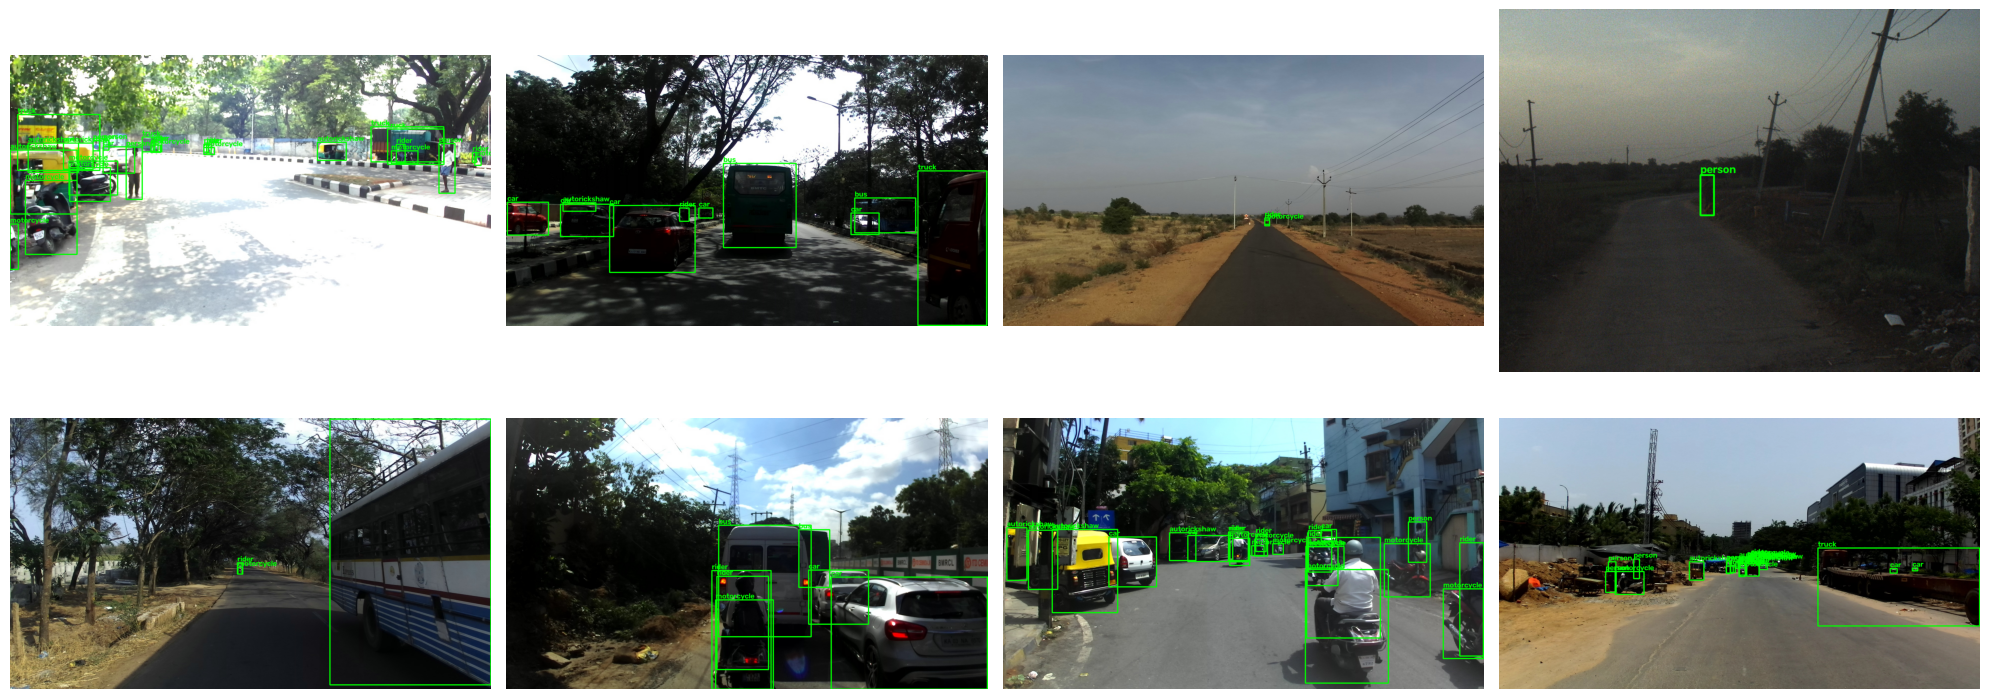

In [21]:
#Verify the labels visually
import cv2, numpy as np, matplotlib.pyplot as plt

imgs = sorted((OUT / "images" / "train").glob("*.jpg"))
pick_imgs = np.random.choice(imgs, 8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, p in zip(axes.ravel(), pick_imgs):
    im = cv2.imread(str(p)); h, w = im.shape[:2]
    lab = OUT / "labels" / "train" / (p.stem + ".txt")
    for line in lab.read_text().splitlines():
        c, cx, cy, bw, bh = line.split(); cx, cy, bw, bh = (float(cx)*w, float(cy)*h, float(bw)*w, float(bh)*h)
        cv2.rectangle(im, (int(cx-bw/2), int(cy-bh/2)), (int(cx+bw/2), int(cy+bh/2)), (0, 255, 0), 3)
        cv2.putText(im, KEEP[int(c)], (int(cx-bw/2), int(cy-bh/2)-5), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.axis("off")
plt.tight_layout(); plt.show()